In [ ]:
#import

from google.colab import files

uplode = files.upload()

In [ ]:
#import
import pandas as pd
import numpy as np
import matplotlib.pyplot
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/healthcare_dataset.csv")

In [ ]:
df.head()

In [ ]:
df.tail()

In [ ]:
df.shape

In [ ]:
df.columns

In [ ]:
df["Date of Admission"]=pd.to_datetime(df["Date of Admission"])

In [ ]:
df["Discharge Date"]=pd.to_datetime(df["Discharge Date"])

In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

In [ ]:
df=df.drop_duplicates()

In [ ]:
df.info()

In [ ]:
#gender distribution
import matplotlib.pyplot as plt

sns.countplot(data=df,x="Gender")
plt.title("Patient Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("No Of Patient")

plt.show()

In [ ]:
#age group distribution

age_bins = [-1, 17, 39, 59, float("inf")]

age_labels = [
    "Child",
    "Young Adults",
    "Middle Adults",
    "Senior"

]

df["Age Group"] = pd.cut(
    df["Age"],
    bins = age_bins,
    labels = age_labels
)

In [ ]:
df["Age Group"].value_counts()

In [ ]:
#visualization

sns.countplot(data=df, x="Age Group")
plt.title("Patient Distribution by Gender")
plt.xlabel("Age Group")
plt.ylabel("No Of Patient")

plt.show()

In [ ]:
sns.countplot(data=df,y="Medical Condition")
plt.title("Patient Distribution by Gender")
plt.xlabel("No Of Patient")
plt.ylabel("Medical Condition")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#medical condition vs gender

sns.countplot(data=df, x="Medical Condition", hue="Gender")

plt.title("Medical Condition Distribution By Gender")
plt.xlabel("Medical Condition")
plt.ylabel("No Of Patient")
plt.xticks(rotation=90)


In [ ]:
#Billing Amount

df["Billing Amount"]

In [ ]:
df["Billing Amount"].head()

In [ ]:
df["Billing Amount"].describe()

In [ ]:
#billing distribution

sns.histplot(
    data=df,
    x="Billing Amount",
    bins=20,
    kde=True)

plt.title("Distribution of Billing Amount")
plt.xlabel("Billing Amount")
plt.ylabel("No Of Patient")
plt.xticks(rotation=90)

plt.show()

In [ ]:
#Billing by Insurance provider

df["Insurance Provider"].value_counts()

In [ ]:
sns.boxplot(data=df,x="Insurance Provider",y="Billing Amount")
plt.title("Billing Amount by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Billing Amount")
plt.xticks(rotation=90)

plt.show()

In [ ]:
#Billing by Admission type
df["Admission Type"].value_counts()

In [ ]:
sns.boxplot( data=df,x="Admission Type",y="Billing Amount")
plt.title("Billing Amount by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Billing Amount")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#medical condition vs billing amount

sns.violinplot( data=df,x="Medical Condition",y="Billing Amount")
plt.title("Billing Amount by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#understanding admission data

df["Date of Admission"].head()

In [ ]:
df["Date of Admission"].dtype

In [ ]:
df["Date of Admission"] = pd.to_datetime(df["Date of Admission"])

In [ ]:
df["Admission Year"] = df["Date of Admission"].dt.year

In [ ]:
df["Admission Month"] = df["Date of Admission"].dt.month

In [ ]:
df[

  [

  "Date of Admission",
  "Admission Year",
  "Admission Month"
  ]

].head()

In [ ]:
#count mountly admission

monthly_admissions=(
    df.groupby("Admission Month")
    .size()
    .reset_index(name="Admissions")

)

In [ ]:
monthly_admissions

,Admission Month,Admissions
0,1,4655
1,2,4210
2,3,4622
3,4,4478
4,5,4555
5,6,4650
6,7,4765
7,8,4785
8,9,4508
9,10,4613


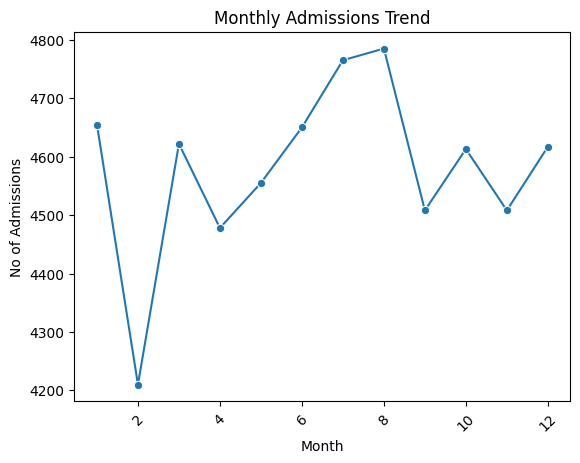

In [ ]:
#Admission trend

sns.lineplot(
    data=monthly_admissions,
    x="Admission Month",
    y="Admissions", marker="o"

)

plt.title("Monthly Admissions Trend")
plt.xlabel("Month")
plt.ylabel("No of Admissions")

plt.xticks(rotation=45)

plt.show()

In [ ]:
#compare admission types over time

monthly_admission_type = (
    df.groupby(
        ["Admission Month", "Admission Type"]
    )

.size()
.reset_index(name="Admissions")

)

In [ ]:
monthly_admission_type.head()

,Admission Month,Admission Type,Admissions
0,1,Elective,1556
1,1,Emergency,1547
2,1,Urgent,1552
3,2,Elective,1415
4,2,Emergency,1452


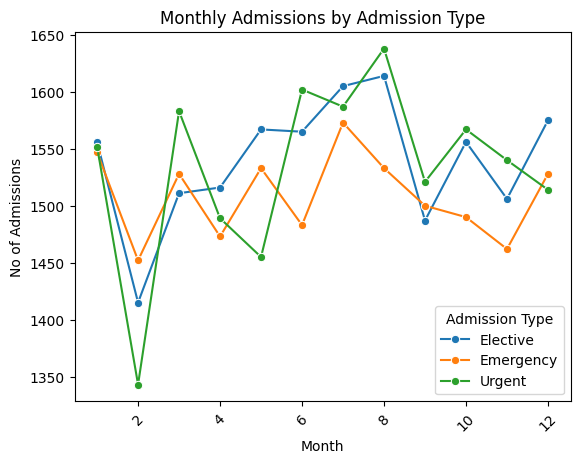

In [ ]:
sns.lineplot(
    data=monthly_admission_type,
    x="Admission Month",
    y="Admissions",
    hue="Admission Type",
    marker="o"
)

plt.title("Monthly Admissions by Admission Type")
plt.xlabel("Month")
plt.ylabel("No of Admissions")
plt.xticks(rotation=45)

plt.show()


In [ ]:
df["Length of Stay"] = (df["Discharge Date"] - df["Date of Admission"]).dt.days

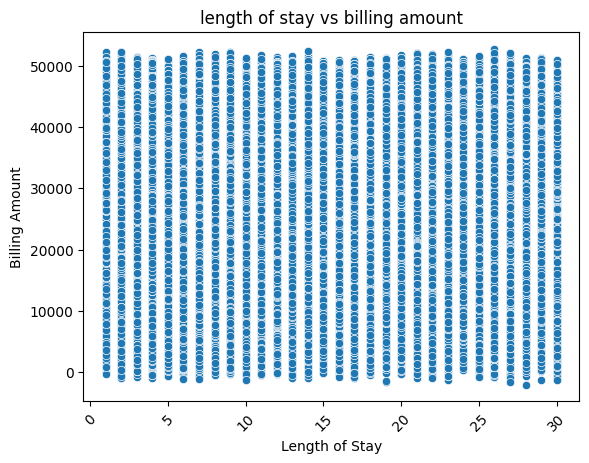

In [ ]:
sns.scatterplot(
    data=df,
    x="Length of Stay",
    y="Billing Amount",

)
plt.title("length of stay vs billing amount")
plt.xlabel("Length of Stay")
plt.ylabel("Billing Amount")
plt.xticks(rotation=45)

plt.show()

In [ ]:
numeric_cols = [
    "Age",
    "Length of Stay",
    "Billing Amount"

]

corr = df[numeric_cols].corr()
corr

,Age,Length of Stay,Billing Amount
Age,1.000000,0.007890,-0.003427
Length of Stay,0.007890,1.000000,-0.004891
Billing Amount,-0.003427,-0.004891,1.000000


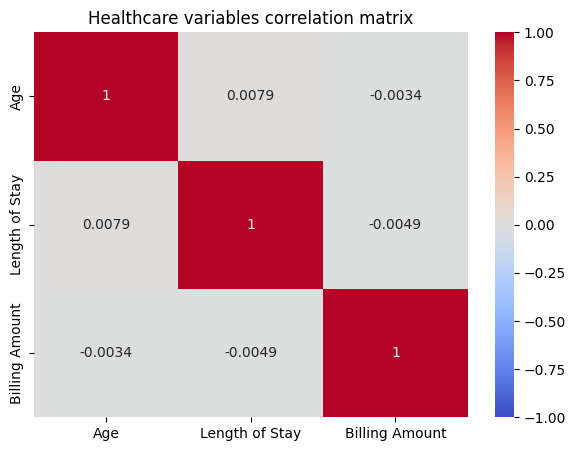

In [ ]:
plt.figure(figsize=(7,5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Healthcare variables correlation matrix")
plt.show()